In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import sklearn

In [3]:
# Requires libomp
import xgboost as xgb

In [4]:
# more penalty if data is off
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [5]:
color_pal = sns.color_palette()
plt.style.use("Solarize_Light2")

In [8]:
df = pd.read_csv("./data/DUK_hourly.csv")
df = df.set_index('period')
# dtype should be a date not a string
df.index = pd.to_datetime(df.index)

<Axes: title={'center': 'DUK Energy Use in MW'}, xlabel='period'>

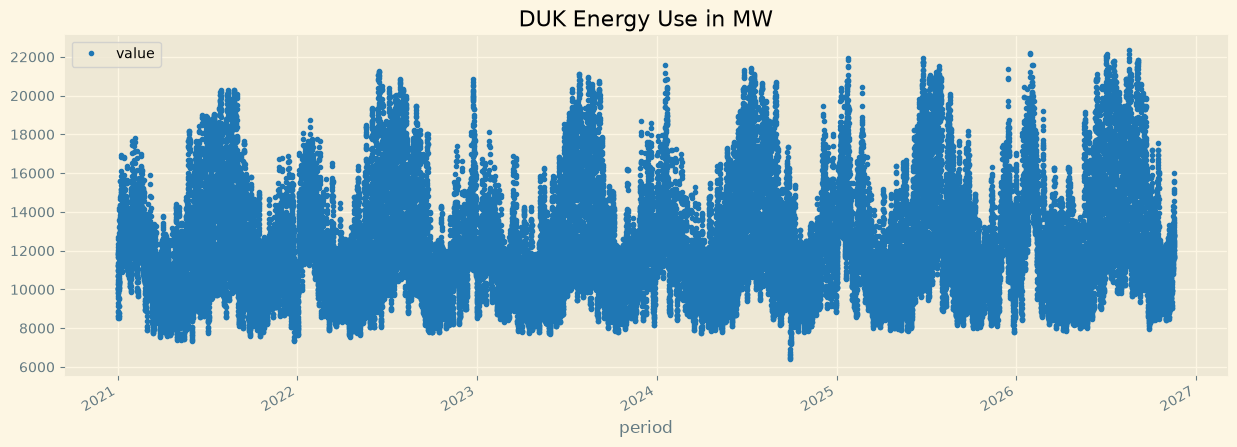

In [9]:
# Plot of original dataset
df.plot(style='.', figsize=(15, 5), color=color_pal[0], title='DUK Energy Use in MW')

Train / Test Split data

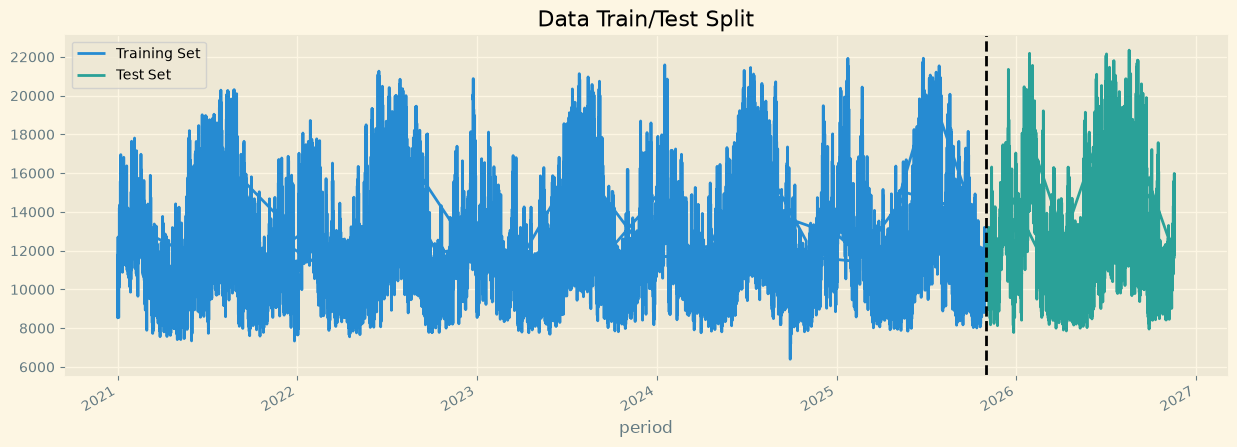

In [12]:
# Split on Jan 2015: Training data is prior to Jan 2015 & Testing data post Jan 2015 
train = df.loc[df.index < '11-01-2025']
test = df.loc[df.index >= '11-01-2025']

# Visualize Data
fig, ax = plt.subplots(figsize=(15, 5))
train.plot(ax=ax, label='Training Set', title='Data Train/Test Split')
test.plot(ax=ax, label='Test Set')
ax.axvline('11-01-2025', color='black', ls='--')
ax.legend(['Training Set', 'Test Set'])
plt.show()


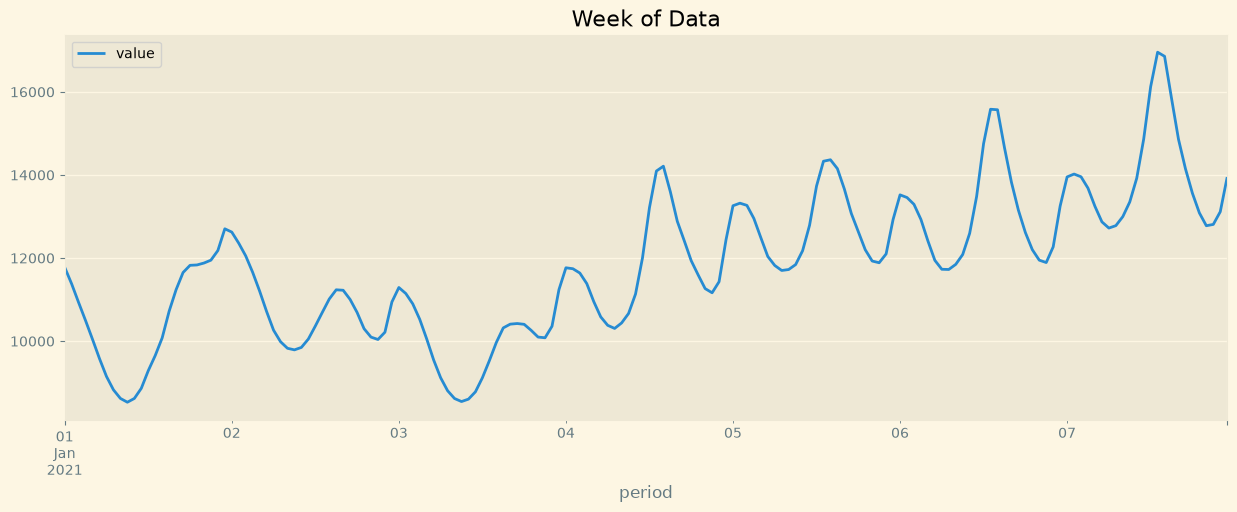

In [14]:
week = df.loc[(df.index >= '2021-01-01') & (df.index < '2021-01-08')].sort_index()
week.plot(figsize=(15, 5), title='Week of Data')
plt.show()

Future Creation

In [17]:
# Create features using the time series index
def create_feature(df):
    df = df.copy()
    df['hour'] = df.index.hour
    df['dayofweek'] = df.index.dayofweek
    df['quarter'] = df.index.quarter
    df['month'] = df.index.month
    df['year'] = df.index.year
    df['dayofyear'] = df.index.dayofyear
    df['dayofmonth'] = df.index.day
    df['weekofyear'] = df.index.isocalendar().week
    return df

df = create_feature(df)


/var/folders/jy/xstwpqs1761_0t5mbjsw1fs00000gn/T/ipykernel_30752/698250861.py:5: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df['dayofweek'] = df.index.dayofweek
/var/folders/jy/xstwpqs1761_0t5mbjsw1fs00000gn/T/ipykernel_30752/698250861.py:9: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  df['dayofyear'] = df.index.dayofyear


In [19]:
df

,value,hour,dayofweek,quarter,month,year,dayofyear,dayofmonth,weekofyear
period,,,,,,,,,
2021-02-19 00:00:00,15505,0,4,1,2,2021,50,19,7
2021-02-18 23:00:00,15165,23,3,1,2,2021,49,18,7
2021-02-18 22:00:00,14927,22,3,1,2,2021,49,18,7
2021-02-18 21:00:00,14983,21,3,1,2,2021,49,18,7
2021-02-18 20:00:00,15195,20,3,1,2,2021,49,18,7
...,...,...,...,...,...,...,...,...,...
2026-10-02 04:00:00,11117,4,4,4,10,2026,275,2,40
2026-10-02 03:00:00,12204,3,4,4,10,2026,275,2,40
2026-10-02 02:00:00,13331,2,4,4,10,2026,275,2,40


Visualize our feature to target Relationship

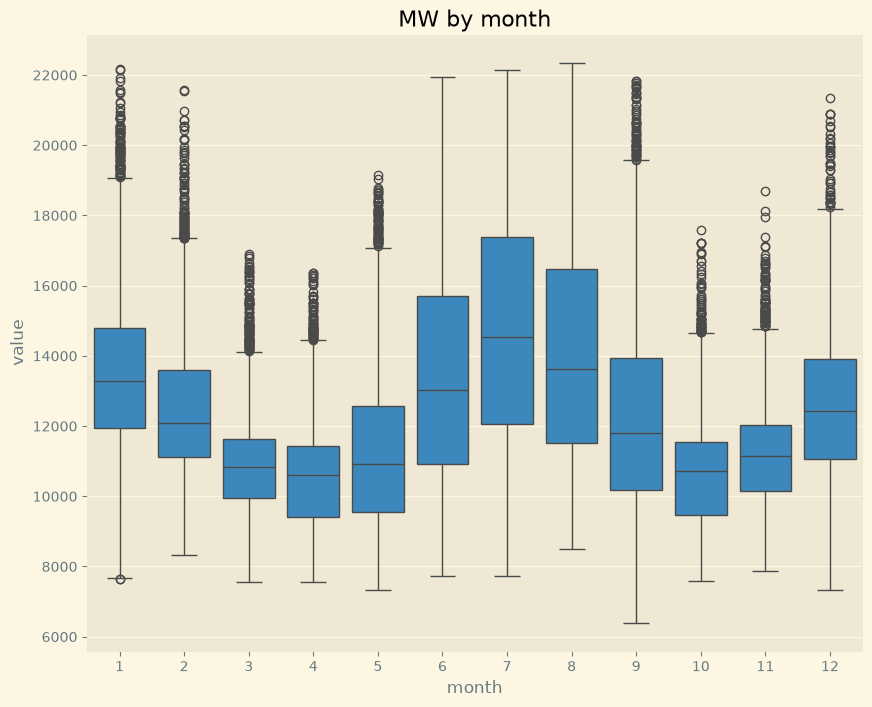

In [21]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.boxplot(data=df, x='month', y='value')
ax.set_title('MW by month')
plt.show()

Create our Model

In [22]:
train = create_feature(train)
test = create_feature(test)

/var/folders/jy/xstwpqs1761_0t5mbjsw1fs00000gn/T/ipykernel_30752/698250861.py:5: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df['dayofweek'] = df.index.dayofweek
/var/folders/jy/xstwpqs1761_0t5mbjsw1fs00000gn/T/ipykernel_30752/698250861.py:9: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  df['dayofyear'] = df.index.dayofyear
/var/folders/jy/xstwpqs1761_0t5mbjsw1fs00000gn/T/ipykernel_30752/698250861.py:5: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df['dayofweek'] = df.index.dayofweek
/var/folders/jy/xstwpqs1761_0t5mbjsw1fs00000gn/T/ipykernel_30752/698250861.py:9: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  df['dayofyear'] = df.

In [23]:
df.columns

Index(['value', 'hour', 'dayofweek', 'quarter', 'month', 'year', 'dayofyear',
       'dayofmonth', 'weekofyear'],
      dtype='str')

In [24]:
df

,value,hour,dayofweek,quarter,month,year,dayofyear,dayofmonth,weekofyear
period,,,,,,,,,
2021-02-19 00:00:00,15505,0,4,1,2,2021,50,19,7
2021-02-18 23:00:00,15165,23,3,1,2,2021,49,18,7
2021-02-18 22:00:00,14927,22,3,1,2,2021,49,18,7
2021-02-18 21:00:00,14983,21,3,1,2,2021,49,18,7
2021-02-18 20:00:00,15195,20,3,1,2,2021,49,18,7
...,...,...,...,...,...,...,...,...,...
2026-10-02 04:00:00,11117,4,4,4,10,2026,275,2,40
2026-10-02 03:00:00,12204,3,4,4,10,2026,275,2,40
2026-10-02 02:00:00,13331,2,4,4,10,2026,275,2,40


In [25]:
FEATURES = ['hour', 'dayofweek', 'quarter', 'month', 'year', 'dayofyear', 'dayofmonth', 'weekofyear']
TARGET = 'value'

In [26]:
X_train = train[FEATURES]
y_train = train[TARGET]

X_test = test[FEATURES]
y_test = test[TARGET]

In [27]:
reg = xgb.XGBRegressor(n_estimators = 1000, early_stopping_rounds=50, learning_rate=0.01)
reg.fit(X_train, y_train,
        eval_set=[(X_train, y_train), (X_test, y_test)],
        verbose=100)

[0]	validation_0-rmse:2604.90857	validation_1-rmse:2993.74500
[100]	validation_0-rmse:1614.80272	validation_1-rmse:2157.02736
[200]	validation_0-rmse:1336.97141	validation_1-rmse:1969.82367
[300]	validation_0-rmse:1211.27344	validation_1-rmse:1936.84438
[357]	validation_0-rmse:1160.73107	validation_1-rmse:1941.98941


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


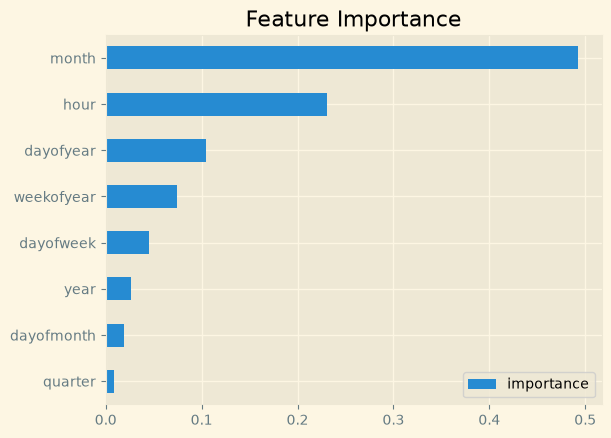

In [28]:
fi = pd.DataFrame(data=reg.feature_importances_,
             index=reg.feature_names_in_,
             columns=['importance'])
fi.sort_values('importance').plot(kind='barh', title='Feature Importance')
plt.show()

In [29]:
test['prediction'] = reg.predict(X_test)

In [30]:
# add prediction column to dataset
df = df.merge(test[['prediction']], how='left', left_index=True, right_index=True)


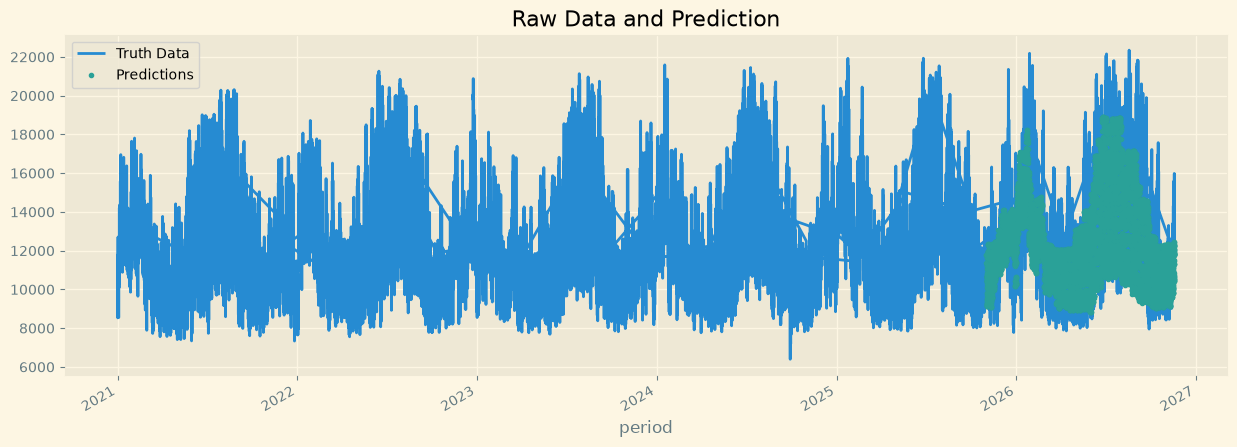

In [32]:
ax = df[['value']].plot(figsize=(15, 5))
df['prediction'].plot(ax=ax, style='.')
plt.legend(['Truth Data', 'Predictions'])
ax.set_title('Raw Data and Prediction')
plt.show()

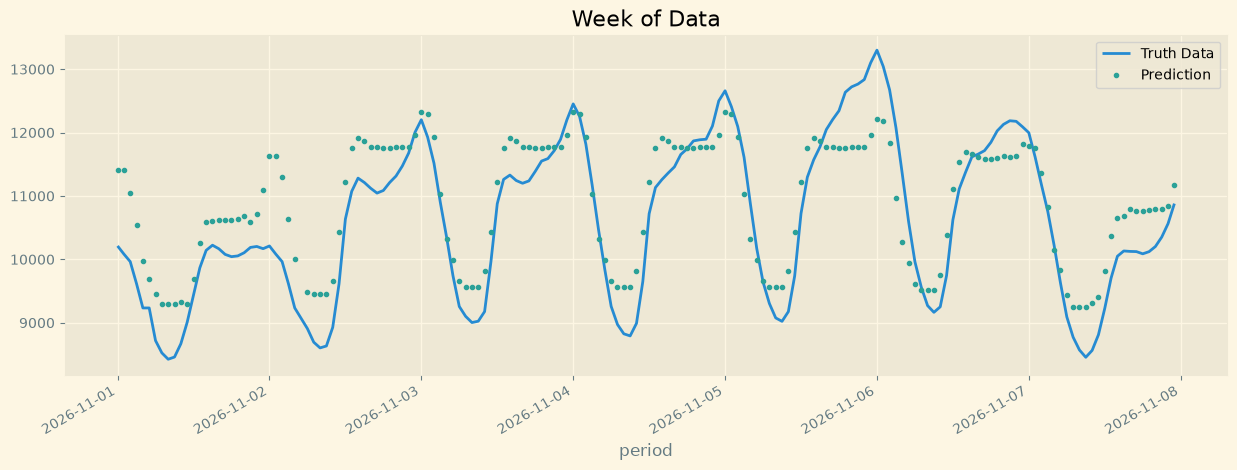

In [41]:
week = df.loc[(df.index >= '2026-11-01') & (df.index < '2026-11-08')].sort_index()
ax = week['value'].plot(figsize=(15, 5), title='Week of Data')
week['prediction'].plot(ax=ax, style='.')
ax.legend(['Truth Data', 'Prediction'])
plt.show()

In [34]:
# Evaluation
score = np.sqrt(mean_squared_error(test['value'], test['prediction']))
print(f'RMSE Score on Test set: {score:0.2f}')

RMSE Score on Test set: 1936.32


In [35]:
test['error'] = np.abs(test[TARGET] - test['prediction'])

In [36]:
test['date'] = test.index.date

In [37]:
test.groupby('date')['error'].mean()

date
2025-11-01     917.396647
2025-11-02     918.924398
2025-11-03     431.323157
2025-11-04     518.455200
2025-11-05     601.938273
                 ...     
2026-11-13     237.904460
2026-11-14    1334.031901
2026-11-15    1821.938680
2026-11-16    1225.996541
2026-11-17    1832.944182
Name: error, Length: 382, dtype: float64

In [38]:
# avg errror each date
test.groupby('date')['error'].mean().sort_values(ascending=False).head(5)


date
2026-02-01    6906.958781
2026-02-02    5394.180827
2025-12-15    5173.670451
2026-01-27    5140.219320
2026-01-31    5094.713094
Name: error, dtype: float64

In [39]:
# best prediction
test.groupby('date')['error'].mean().sort_values(ascending=True).head(5)

date
2026-05-07    227.092733
2026-11-13    237.904460
2026-11-08    245.257039
2026-11-11    259.305054
2026-11-09    259.630941
Name: error, dtype: float64

#add more cross val and features